In [122]:
import matplotlib.pyplot as plt
import pandas as pd

In [123]:
df = pd.read_csv('../data/MetroPT3(AirCompressor).csv', index_col=0, parse_dates=["timestamp"])
df = df.set_index("timestamp")
print(df.shape)
df.head()

(1516948, 15)


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
timestamp,,,,,,,,,,,,,,,
2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


In [124]:
print("Shape: ", df.shape)
print("Von:", df.index.min())
print("Bis:", df.index.max())
print("Gesamtzeitraum:", df.index.max() - df.index.min())
print("\nColumns: ", df.columns)
print("\nDtypes: ", df.dtypes)

Shape:  (1516948, 15)
Von: 2020-02-01 00:00:00
Bis: 2020-09-01 03:59:50
Gesamtzeitraum: 213 days 03:59:50

Columns:  Index(['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature',
       'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS',
       'Pressure_switch', 'Oil_level', 'Caudal_impulses'],
      dtype='str')

Dtypes:  TP2                float64
TP3                float64
H1                 float64
DV_pressure        float64
Reservoirs         float64
Oil_temperature    float64
Motor_current      float64
COMP               float64
DV_eletric         float64
Towers             float64
MPG                float64
LPS                float64
Pressure_switch    float64
Oil_level          float64
Caudal_impulses    float64
dtype: object


  - 1.5M Zeilen
  - 7 analoge Signale: TP2, TP3, H1, DV_pressure, Reservoirs, Oil_temperature, Motor_current
  - 8 digitale Signale: COMP, DV_eletric, Towers, MPG, LPS, Pressure_switch, Oil_level, Caudal_impulses


In [125]:
print("\nMissing values: ", df.isnull().sum())
print("Duplicate:", df.index.duplicated().sum())


Missing values:  TP2                0
TP3                0
H1                 0
DV_pressure        0
Reservoirs         0
Oil_temperature    0
Motor_current      0
COMP               0
DV_eletric         0
Towers             0
MPG                0
LPS                0
Pressure_switch    0
Oil_level          0
Caudal_impulses    0
dtype: int64
Duplicate: 0


In [126]:
gap = df.index.to_series().diff()
print(gap.value_counts().head())

timestamp
0 days 00:00:10    1337521
0 days 00:00:09     128277
0 days 00:00:12      38321
0 days 00:00:13       7988
0 days 00:00:11       4471
Name: count, dtype: int64


In [127]:
big = gap[gap > pd.Timedelta("1min")]
print("Lücken > 1 min:", len(big))
print("Gesamtdauer:", big.sum())
rate = big.sum() / (df.index.max() - df.index.min())
print(f"Anteil fehlender Zeit: {rate:.1%}")
top = big.sort_values(ascending=False).head()
print(pd.DataFrame({
    "tag_start": (top.index - top.values).day_name(),
    "start": top.index - top.values,
    "tag_ende": top.index.day_name(),
    "ende": top.index,
    "dauer": top.values,
}).to_string(index=False))

Lücken > 1 min: 331
Gesamtdauer: 37 days 21:31:03
Anteil fehlender Zeit: 17.8%
tag_start               start  tag_ende                ende           dauer
 Saturday 2020-04-25 01:10:51    Monday 2020-04-27 01:12:49 2 days 00:01:58
 Saturday 2020-06-27 10:53:07    Sunday 2020-06-28 23:07:43 1 days 12:14:36
   Friday 2020-02-28 23:57:08    Sunday 2020-03-01 04:00:09 1 days 04:03:01
  Tuesday 2020-08-04 07:42:28 Wednesday 2020-08-05 08:23:01 1 days 00:40:33
   Sunday 2020-05-24 00:39:23    Monday 2020-05-25 01:14:14 1 days 00:34:51


In [138]:
g = df.index.to_series().diff().dt.total_seconds()
g = g[g > 14]                                    # bỏ khoảng cách bình thường 9–13 s
group = pd.cut(g / 60, [14/60, 0.5, 1, 5, 60, 360, 1440, 1e6],
               labels=["14–30 s", "30s–1 min", "1–5 min", "5–60 min",
                       "1–6 h", "6–24 h", "> 1 Tag"])
print(pd.DataFrame({
    "anzahl":  group.value_counts().sort_index(),
    "summe_h": (g.groupby(group).sum() / 3600).round(1),
}))

           anzahl  summe_h
timestamp                 
14–30 s        33      0.2
30s–1 min       0      NaN
1–5 min        56      3.3
5–60 min      115     37.7
1–6 h         128    399.4
6–24 h         27    307.6
> 1 Tag         5    161.6


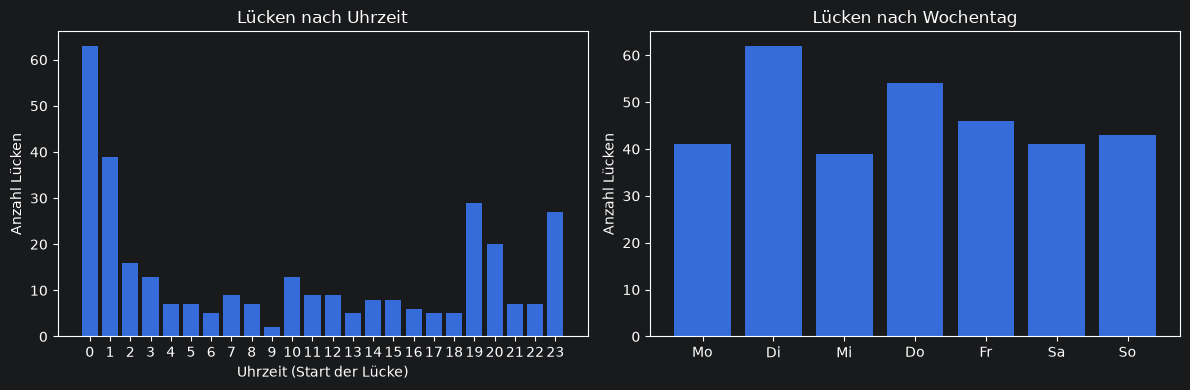

In [129]:
import matplotlib.pyplot as plt

klein = big[big < pd.Timedelta("1D")]
start = klein.index - klein.values

by_hour = pd.Series(start.hour).value_counts().reindex(range(24), fill_value=0)
by_day = pd.Series(start.day_name()).value_counts().reindex(thu_tu, fill_value=0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].bar(by_hour.index, by_hour.values)
ax[0].set_xticks(range(24))
ax[0].set_xlabel("Uhrzeit (Start der Lücke)")
ax[0].set_ylabel("Anzahl Lücken")
ax[0].set_title("Lücken nach Uhrzeit")

ax[1].bar(["Mo","Di","Mi","Do","Fr","Sa","So"], by_day.values)
ax[1].set_ylabel("Anzahl Lücken")
ax[1].set_title("Lücken nach Wochentag")

plt.tight_layout()
plt.show()

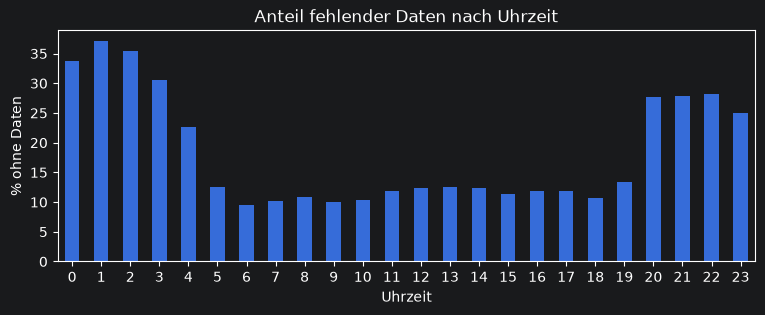

In [130]:
voll = df.resample("10s").size()
fehlt = (voll == 0)
anteil = fehlt.groupby(fehlt.index.hour).mean() * 100

anteil.plot.bar(figsize=(9, 3), rot=0)
plt.xlabel("Uhrzeit"); plt.ylabel("% ohne Daten")
plt.title("Anteil fehlender Daten nach Uhrzeit")
plt.show()

Bei einem regulären Abtastintervall von 10 s gibt es 331 Lücken > 1 min. Zusammen umfassen sie 37,9 Tage, also 17,8 % des Zeitraums. Die Lücken treten vor allem abends (ca. 20–4 Uhr) auf und wiederholen sich täglich. Das deutet auf planmäßige Betriebspausen hin, die Fehlwerte sind also nicht zufällig (kein MCAR). Einzelne längere Lücken tagsüber könnten auf Wartung oder Störungen hindeuten. Längere Lücken werden daher nicht interpoliert; stattdessen werden die Daten in zusammenhängende Segmente aufgeteilt.

In [131]:
analog  = ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs", "Oil_temperature", "Motor_current"]
digital = ["COMP", "DV_eletric", "Towers", "MPG", "LPS", "Pressure_switch", "Oil_level", "Caudal_impulses"]

print(df[analog].describe().round(2))
for c in digital:
    print(c, df[c].value_counts(normalize=True).round(3).to_dict())

              TP2         TP3          H1  DV_pressure  Reservoirs  \
count  1516948.00  1516948.00  1516948.00   1516948.00  1516948.00   
mean         1.37        8.98        7.57         0.06        8.99   
std          3.25        0.64        3.33         0.38        0.64   
min         -0.03        0.73       -0.04        -0.03        0.71   
25%         -0.01        8.49        8.25        -0.02        8.49   
50%         -0.01        8.96        8.78        -0.02        8.96   
75%         -0.01        9.49        9.37        -0.02        9.49   
max         10.68       10.30       10.29         9.84       10.30   

       Oil_temperature  Motor_current  
count       1516948.00     1516948.00  
mean             62.64           2.05  
std               6.52           2.30  
min              15.40           0.02  
25%              57.78           0.04  
50%              62.70           0.04  
75%              67.25           3.81  
max              89.05           9.30  
COMP {1.0

## Beobachtungen aus der deskriptiven Statistik
**TP2 und Motor_current**
- Meist liegen die Werte bei 0, nur manchmal sind sie hoch. Deshalb ist der Mittelwert viel größer als der Median.
- Grund: Der Kompressor pumpt nur selten. Wenn er pumpt, steigen TP2 und der Motorstrom.
- Der Motorstrom zeigt sogar drei Zustände: aus (~0 A), Leerlauf (~4 A) und Pumpen (~6 A).

**H1**
- H1 verhält sich genau umgekehrt zu TP2.
- Pumpt der Kompressor, ist TP2 hoch und H1 bei ~0. Pumpt er nicht, ist TP2 bei ~0 und H1 hoch (~8–9 bar).

**TP3 und Reservoirs**
Beide Signale haben fast genau dieselben Werte -> brauchen nur eines davon.

**DV_pressure**
- Fast immer bei 0. Nur selten gibt es kurze Spitzen (bis 9,8 bar).
- Diese Spitzen entstehen, wenn Luft abgelassen wird. Nur dann ist das Signal interessant.

**COMP, DV_eletric und MPG**
- Alle drei zeigen dasselbe: Pumpt der Kompressor oder nicht?

**LPS**
- LPS warnt vor zu niedrigem Druck (unter 7 bar).
- Es ist nur in 0,3 % der Zeit aktiv. Wenn es auftritt, ist das ungewöhnlich.

**Oil_temperature**
- Normalerweise liegt die Öltemperatur zwischen 57 und 67 °C.
- Sehr niedrige Werte (bis 15 °C) kommen vermutlich vom Kaltstart. Sehr hohe Werte (bis 89 °C) zeigen eine hohe Belastung.TP2 und Motor_current

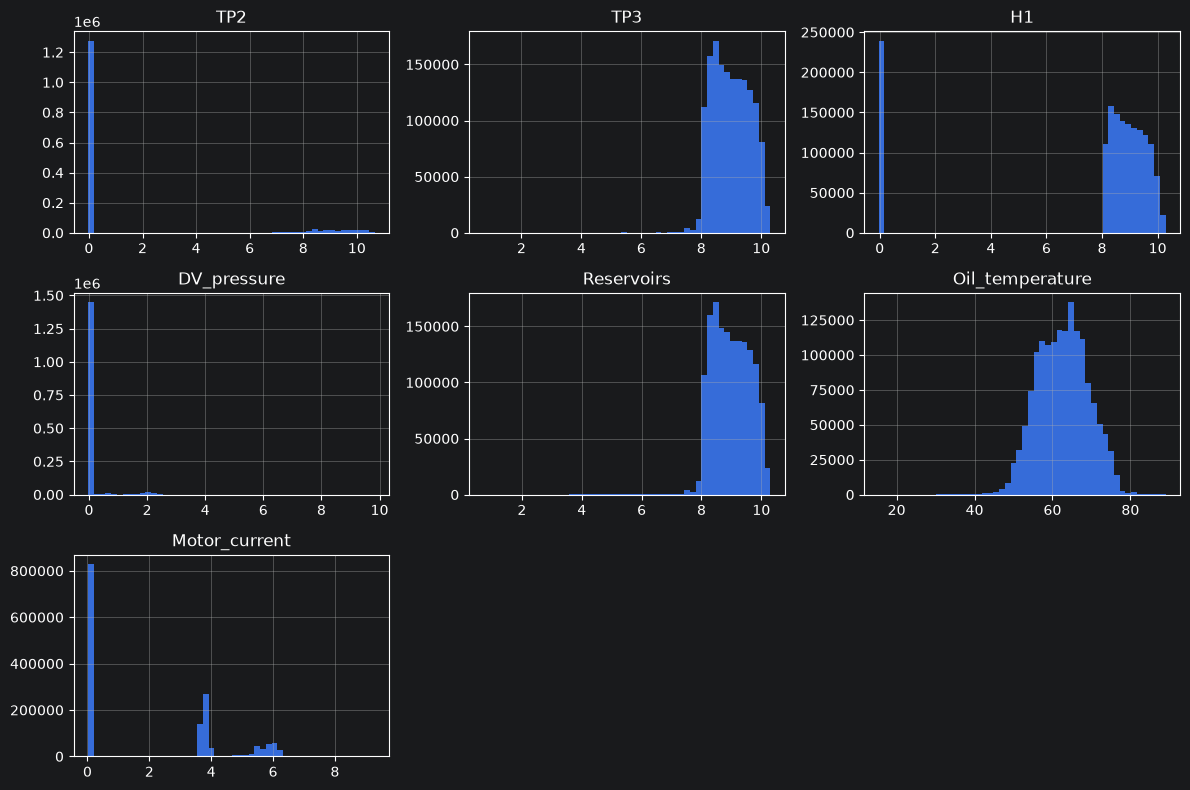

                 TP3  Reservoirs
TP3         1.000000    0.999993
Reservoirs  0.999993    1.000000


In [132]:
df[analog].hist(bins=50, figsize=(12, 8)); plt.tight_layout(); plt.show()
print(df[["TP3", "Reservoirs"]].corr())

## Beobachtungen aus den Histogrammen
- TP2, H1: zwei getrennte Zustände (~0 bar und ~8–10 bar), spiegelbildlich zueinander. Keine Normalverteilung.
- Motor_current: drei Zustände: ~0 A (aus), ~4 A (Leerlauf), ~6 A (unter Last).
- TP3 und Reservoirs: nahezu identisch, gleichmäßig zwischen ca. 8 und 10 bar (Sägezahnverlauf). Eines der beiden ist redundant.
- Oil_temperature: um ~62 °C, Ausläufer nach unten (Kaltstart) und bis ~89 °C bei hoher Last.
- DV_pressure: fast immer ~0 bar, Werte > 1 bar sehr selten (nur bei Entlüftung).

<Axes: title={'center': 'LPS pro Tag'}, xlabel='timestamp'>

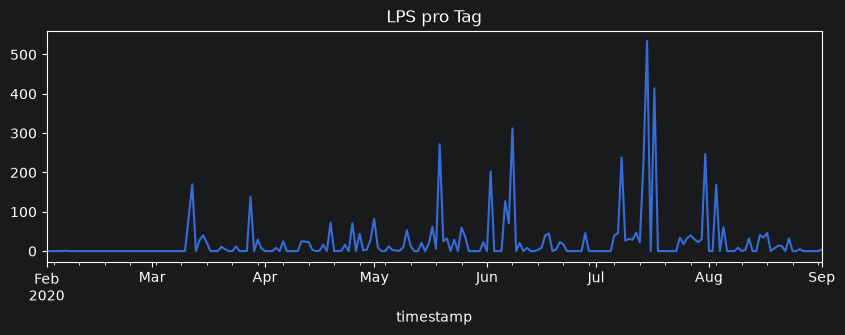

In [133]:
df["LPS"].resample("1D").sum().plot(figsize=(10, 3), title="LPS pro Tag")

1. Februar: LPS ist durchgehend 0, es gibt keine einzige Niederdruckwarnung.
2. Ab Mitte März tritt LPS auf, mit einem ersten Peak von ca. 170 am 12.03. Danach ist LPS fast täglich in geringem Umfang aktiv. Das passt zur Verhaltensänderung ab März (der Kompressor pumpt häufiger).
3. Die größten Peaks:
    - Mitte Juli: ca. 535 (15.07., Luftleck #4) und ca. 415 (17.07.). Das ist der höchste Peak im gesamten Diagramm.
    - Anfang Juni: ca. 310 (08.06.) und ca. 205 (02.06.), rund um Luftleck #3.
    - Mitte Mai (ca. 270), Anfang Juli (ca. 240) sowie Ende Juli/Anfang August (ca. 250 und 170): ohne zeitlichen Zusammenhang mit einem dokumentierten Luftleck.
4. Rund um die Luftlecks #1 (18.04.) und #2 (29.–30.05.) zeigt sich kein deutlicher Peak.

## Beobachtungen aus dem Pumpzyklus (03.02.2020, 07:00–08:30)

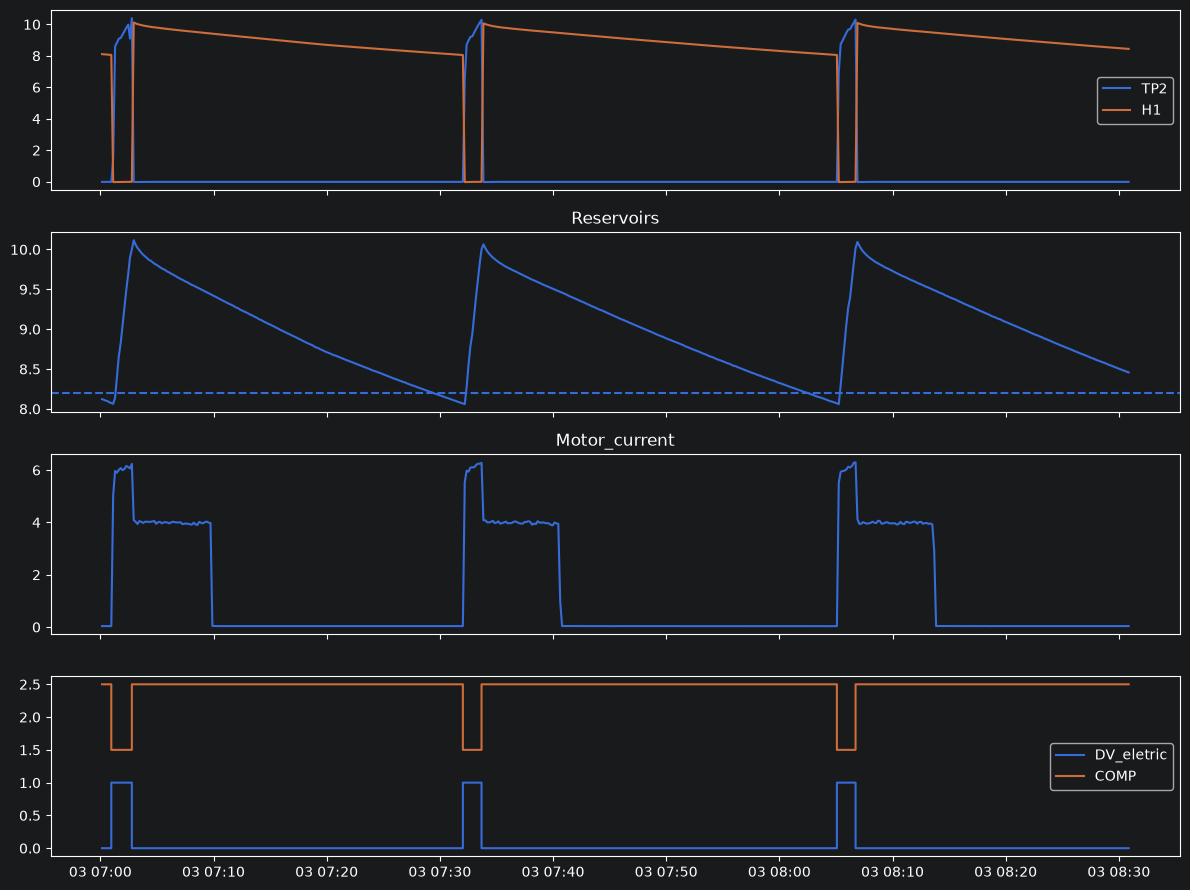

In [134]:
w = df.loc["2020-02-03 07:00":"2020-02-03 08:30"]

fig, ax = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
ax[0].plot(w.index, w.TP2, label="TP2"); ax[0].plot(w.index, w.H1, label="H1"); ax[0].legend()
ax[1].plot(w.index, w.Reservoirs); ax[1].axhline(8.2, ls="--"); ax[1].set_title("Reservoirs")
ax[2].plot(w.index, w.Motor_current); ax[2].set_title("Motor_current")
ax[3].step(w.index, w.DV_eletric, label="DV_eletric"); ax[3].step(w.index, w.COMP + 1.5, label="COMP"); ax[3].legend()
plt.tight_layout(); plt.show()


- Der Kompressor arbeitet in sehr regelmäßigen Zyklen: ca. 2 min Pumpen, ca. 30 min Pause (Zyklusdauer ca. 32 min).
- Der Druck im Reservoir verläuft sägezahnförmig: Pumpen ab ca. 8,1 bar, Stopp bei ca. 10,1 bar. Der Druck steigt schnell (ca. 1 bar/min) und fällt langsam (ca. 0,06 bar/min) durch den normalen Luftverbrauch.
- Der Motorstrom zeigt drei Stufen: ~6 A (Pumpen) → ~4 A (Leerlauf, ca. 7 min) → ~0 A (aus).
- DV_eletric und COMP sowie TP2 und H1 schalten jeweils exakt gegenläufig.
- Da das Normalverhalten sehr regelmäßig ist, lassen sich daraus Features ableiten: Pausendauer, Pumpdauer, Druckanstiegs- und Druckabfallrate. Insbesondere eine schnellere Druckabnahme in der Pause wäre ein direkte Hinweis auf ein Luftleck.

In [135]:
corr = df[analog].corr().round(2)
print(corr)

                  TP2   TP3    H1  DV_pressure  Reservoirs  Oil_temperature  \
TP2              1.00 -0.01 -0.96         0.42       -0.01             0.25   
TP3             -0.01  1.00  0.22        -0.15        1.00             0.40   
H1              -0.96  0.22  1.00        -0.43        0.23            -0.16   
DV_pressure      0.42 -0.15 -0.43         1.00       -0.15             0.34   
Reservoirs      -0.01  1.00  0.23        -0.15        1.00             0.40   
Oil_temperature  0.25  0.40 -0.16         0.34        0.40             1.00   
Motor_current    0.70  0.41 -0.60         0.30        0.41             0.53   

                 Motor_current  
TP2                       0.70  
TP3                       0.41  
H1                       -0.60  
DV_pressure               0.30  
Reservoirs                0.41  
Oil_temperature           0.53  
Motor_current             1.00  


Die Korrelationsanalyse zeigt: TP3 und Reservoirs sind identisch (r = 1,00), daher wird TP3 entfernt. TP2 und H1 verhalten sich gegenläufig (r = −0,96) und enthalten damit dieselbe Information. Der Motorstrom hängt mit TP2 (r = 0,70) und der Öltemperatur (r = 0,53) zusammen. Da die Korrelation nur lineare Zusammenhänge misst, wird sie zusammen mit dem Zyklusdiagramm interpretiert.


In [136]:
df.to_parquet("../data/processed/df_raw.parquet")
print("Gespeichert:", df.shape)

Gespeichert: (1516948, 15)
